# 08 发生率预报：2017–2025 测试分段的网格与归属

BNBU DS 2043 / DI-3 新锁定分段。本笔记本只重算 **2° × 30 天** 格窗归属与阳性率。不训练 ML，不改写 `07_external`、上一轮 `08_rate_forecast/` 父目录快照，不推送 GitHub。

产出目录：`/workspace/08_rate_forecast/split_2017_2025/`。上一轮（测试 2017–2024、holdout 2025–2026）文件保留在 `/workspace/08_rate_forecast/` 作为对照。

## 0 新锁定分段

30 天箱仍从 `1965-01-01T00:00:00Z` 起。窗只有整段落在分段内才属于该分段。

- 训练不变：`[1965-01-01, 2009-01-01)`
- 验证不变：`[2009-01-01, 2017-01-01)`
- **测试改为** `[2017-01-01, 2026-01-01)`，即 2017–2025（含 2025）
- **后期 holdout 改为** `[2026-01-01, 2026-11-26T07:43:30Z]`

边界变化：旧跨段窗 `2024-12-17` 至 `2025-01-16` 现在整段落在测试期内，必须计入测试标签。新的被排除跨段窗是跨越 `2026-01-01` 的 30 天窗。越过抓取终点的最后不完整窗仍不进入 holdout 标签。被排除窗内的事件仍可按发震时刻进入后续窗历史。

主样本仍是 USGS 1965–2024（28,044 / 4,220 / 2,188 / 74 / 6,334），不把 2025/2026 追加进主表文件。2025 年来自已采集的 holdout 目录，记入测试；2026 年只记入 holdout。

**协议说明：** 2025 年此前已作为 2025–2026 后期 holdout 评过分，那些基线数字已经展示给用户；在本分段下 2025 不再是未见的后期检查。

In [1]:
%matplotlib inline
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from rate_forecast_lib import (
    LOCK_COUNTS, HOLDOUT_LOCK, CountMismatchError, SPLIT_BOUNDS,
    load_and_verify_catalog, build_windows, build_cell_mask,
    assign_events, mark_historical_activity, summarize_counts,
    boundary_event_counts,
)
from rate_forecast_plots import (
    FIG, plot_cell_mask, plot_hist_active, plot_prevalence, plot_positive_series,
)

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 140)
ROOT = Path("/workspace/08_rate_forecast/split_2017_2025")
FIG.mkdir(parents=True, exist_ok=True)
print("working dir", ROOT)
print("split bounds:")
for k, (a, b) in SPLIT_BOUNDS.items():
    print(f"  {k}: [{a}, {b})")

working dir /workspace/08_rate_forecast/split_2017_2025
split bounds:
  train: [1965-01-01 00:00:00+00:00, 2009-01-01 00:00:00+00:00)
  val: [2009-01-01 00:00:00+00:00, 2017-01-01 00:00:00+00:00)
  test: [2017-01-01 00:00:00+00:00, 2026-01-01 00:00:00+00:00)
  holdout: [2026-01-01 00:00:00+00:00, 2026-11-26 07:43:30+00:00)


## 1 核对主目录，并按年拆开 2025 / 2026

主表过滤上限仍是 2025-01-01（不含），与测试段右端 2026-01-01 分开，避免把 2025 写进 1965–2024 主表。

In [2]:
try:
    ev_main, ev_later = load_and_verify_catalog()
except CountMismatchError as exc:
    raise SystemExit(f"STOP: counts disagree with the locked region definition.\n{exc}")

got = {
    "all": len(ev_main),
    "china_rectangle": int(ev_main.china_rectangle.sum()),
    "PB_Pacific": int(ev_main.PB_Pacific.sum()),
    "overlap": int((ev_main.china_rectangle & ev_main.PB_Pacific).sum()),
    "union": int(ev_main.in_union.sum()),
}
print("1965-2024 main:", got, "match", got == LOCK_COUNTS)
print("later catalog all/union:", len(ev_later), int(ev_later.in_union.sum()), "locked file", HOLDOUT_LOCK)
print(ev_later.groupby("catalog_role").agg(n=("id", "size"), union=("in_union", "sum"), rect=("china_rectangle", "sum"), pac=("PB_Pacific", "sum")))
print("main max time", ev_main.time_utc.max(), "2025 min/max", ev_later.loc[ev_later.catalog_role=="year_2025_in_test","time_utc"].min(), ev_later.loc[ev_later.catalog_role=="year_2025_in_test","time_utc"].max())
print("2026 min/max", ev_later.loc[ev_later.catalog_role=="year_2026_holdout","time_utc"].min(), ev_later.loc[ev_later.catalog_role=="year_2026_holdout","time_utc"].max())
print("id overlap main vs later:", len(set(ev_main.id) & set(ev_later.id)))
ev_all = pd.concat([ev_main, ev_later], ignore_index=True)

1965-2024 main: {'all': 28044, 'china_rectangle': 4220, 'PB_Pacific': 2188, 'overlap': 74, 'union': 6334} match True
later catalog all/union: 949 190 locked file {'all': 949, 'union': 190}
                     n  union  rect  pac
catalog_role                            
year_2025_in_test  514    108    67   41
year_2026_holdout  435     82    62   21
main max time 2024-12-30 05:41:06.678000+00:00 2025 min/max 2025-01-01 04:39:18.208000+00:00 2025-12-31 14:26:57.992000+00:00
2026 min/max 2026-01-01 01:53:01.809000+00:00 2026-11-25 01:38:45.672000+00:00
id overlap main vs later: 0


## 2 时间窗：确认旧跨段窗进入测试，新跨段窗被排除

In [3]:
windows = build_windows()
print(windows.groupby(["split", "boundary_note"]).size().rename("n_windows"))
print()
print("windows not assigned to a split:")
print(windows.loc[windows.split == "none", ["window_id", "window_start", "window_end", "boundary_note"]].to_string(index=False))
print()
print("window 730 (old straddle, must now be test):")
print(windows.loc[windows.window_id == 730, ["window_id", "window_start", "window_end", "split", "boundary_note"]].to_string(index=False))
print("first/last complete test and holdout:")
for sp in ["test", "holdout"]:
    sub = windows.loc[windows.split == sp]
    print(sp, int(sub.window_id.min()), "->", int(sub.window_id.max()), "n=", len(sub), sub.iloc[0].window_start, "to", sub.iloc[-1].window_end)

split    boundary_note        
holdout  holdout                   10
none     incomplete_holdout         1
         straddle_test_holdout      1
         straddle_train_val         1
         straddle_val_test          1
test     test                     108
train    train                    535
val      val                       97
Name: n_windows, dtype: int64

windows not assigned to a split:
 window_id              window_start                window_end         boundary_note
       535 2008-12-11 00:00:00+00:00 2009-01-10 00:00:00+00:00    straddle_train_val
       633 2016-12-29 00:00:00+00:00 2017-01-28 00:00:00+00:00     straddle_val_test
       742 2025-12-12 00:00:00+00:00 2026-01-11 00:00:00+00:00 straddle_test_holdout
       753 2026-11-07 00:00:00+00:00 2026-12-07 00:00:00+00:00    incomplete_holdout

window 730 (old straddle, must now be test):
 window_id              window_start                window_end split boundary_note
       730 2024-12-17 00:00:00+00:00 2025-01-16

## 3 空间网格与掩膜（几何规则不变）

union/rect/pac/overlap: 3594 988 2632 26


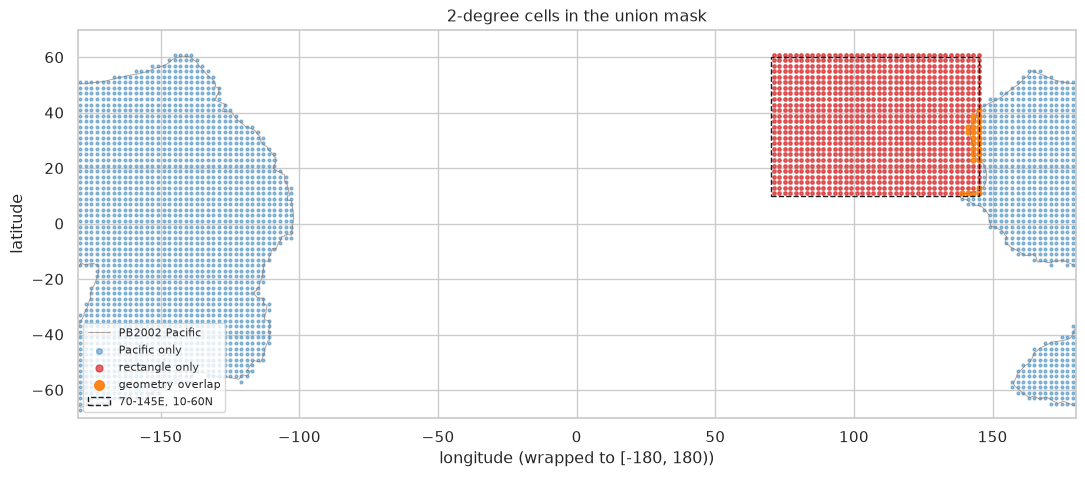

In [4]:
cells = build_cell_mask()
print("union/rect/pac/overlap:", int(cells.in_union_mask.sum()), int(cells.intersects_rectangle.sum()), int(cells.intersects_pacific.sum()), int((cells.intersects_rectangle & cells.intersects_pacific).sum()))
fig = plot_cell_mask(cells, FIG / "grid_mask_cells.png")
plt.show(); plt.close(fig)

## 4 事件归属与阳性率

union events outside mask: 0
historically active (unchanged rule, train period only):
historically_active_rectangle    327
historically_active_pacific      224
historically_active_union        538
dtype: int64
catalog_role       split  
main_1965_2024     none         16
                   test        635
                   train      4553
                   val        1130
year_2025_in_test  none         11
                   test         97
year_2026_holdout  holdout      74
                   none          8
Name: n, dtype: int64


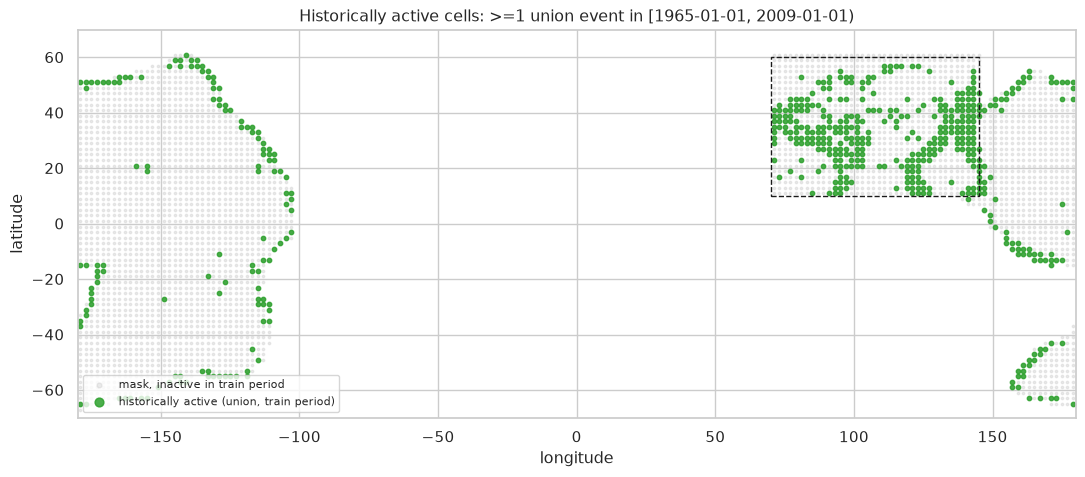

,region,split,n_cells_all,n_windows,n_cell_windows_all,n_events_in_complete_windows,n_positive_cell_windows_all,prevalence_all,n_cells_hist_active,n_cell_windows_hist_active,n_positive_cell_windows_hist_active,prevalence_hist_active,n_unique_positive_cells_in_split
0,china_rectangle,train,988,535,528580,3056,2385,0.004512,327,174945,2385,0.013633,327
1,china_rectangle,val,988,97,95836,725,427,0.004456,327,31719,413,0.013021,142
2,china_rectangle,test,988,108,106704,491,400,0.003749,327,35316,382,0.010817,142
3,china_rectangle,holdout,988,10,9880,56,49,0.004960,327,3270,46,0.014067,37
4,pacific,train,2632,535,1408120,1526,1152,0.000818,224,119840,1152,0.009613,224
5,pacific,val,2632,97,255304,435,270,0.001058,224,21728,249,0.011460,108
6,pacific,test,2632,108,284256,256,232,0.000816,224,24192,202,0.008350,113
7,pacific,holdout,2632,10,26320,19,19,0.000722,224,2240,16,0.007143,18
8,union,train,3594,535,1922790,4553,3509,0.001825,538,287830,3509,0.012191,538
9,union,val,3594,97,348618,1130,683,0.001959,538,52186,651,0.012475,244


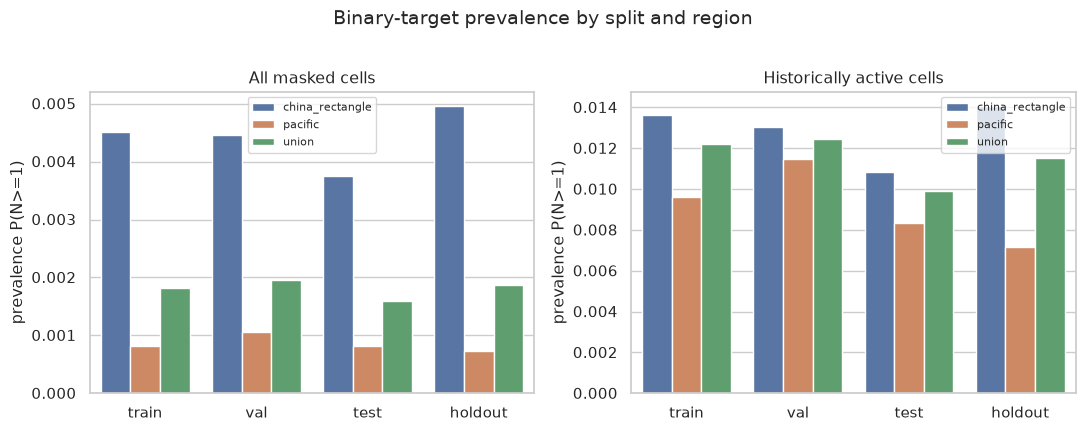

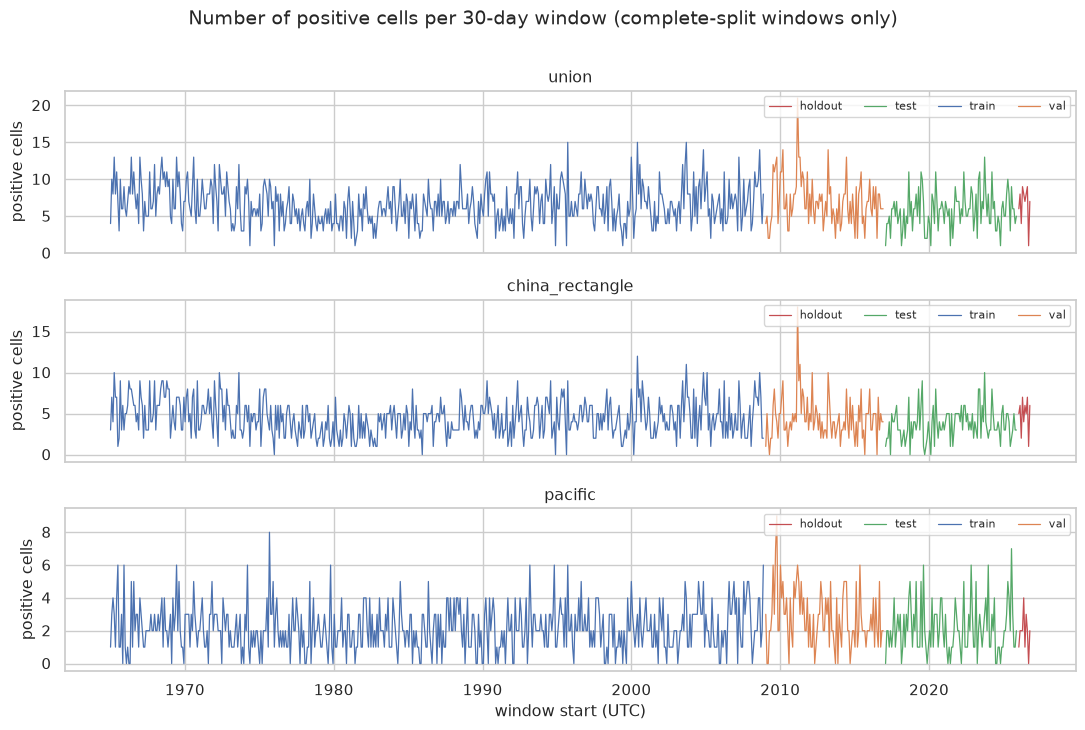

In [5]:
ev = assign_events(ev_all, windows)
cells = mark_historical_activity(cells, ev)
union = ev.loc[ev.in_union]
missing = union.loc[~union.cell_id.isin(set(cells.loc[cells.in_union_mask, "cell_id"]))]
print("union events outside mask:", len(missing))
if len(missing):
    raise SystemExit("STOP: assignment left union events outside the mask")
print("historically active (unchanged rule, train period only):")
print(cells[["historically_active_rectangle", "historically_active_pacific", "historically_active_union"]].sum())
print(union.groupby(["catalog_role", "split"], dropna=False).size().rename("n"))
windows.to_csv(ROOT / "windows.csv", index=False)
cells.to_csv(ROOT / "cells_mask.csv", index=False)
union.to_csv(ROOT / "events_union_assigned.csv", index=False)
fig = plot_hist_active(cells, FIG / "grid_hist_active_cells.png")
plt.show(); plt.close(fig)

prev = summarize_counts(ev, windows, cells)
prev.to_csv(ROOT / "prevalence_by_split_region.csv", index=False)
display(prev)
fig = plot_prevalence(prev, FIG / "grid_prevalence_bars.png")
plt.show(); plt.close(fig)

recs = []
for region, flag in [("china_rectangle", "china_rectangle"), ("pacific", "PB_Pacific"), ("union", "in_union")]:
    sub = ev.loc[ev[flag] & ev.entirely_in_split]
    g = sub.groupby(["split", "window_id"], as_index=False).agg(n_events=("id", "size"), n_positive_cells=("cell_id", "nunique"))
    g["region"] = region
    recs.append(g)
series = pd.concat(recs, ignore_index=True)
gridw = pd.concat([windows.loc[windows.entirely_in_split, ["window_id", "split"]].assign(region=r) for r in ["china_rectangle", "pacific", "union"]], ignore_index=True)
series = gridw.merge(series.drop(columns=["split"]), on=["region", "window_id"], how="left")
series["n_events"] = series["n_events"].fillna(0).astype(int)
series["n_positive_cells"] = series["n_positive_cells"].fillna(0).astype(int)
series.to_csv(ROOT / "window_observed_series.csv", index=False)
fig = plot_positive_series(series, windows, FIG / "grid_positive_cells_series.png")
plt.show(); plt.close(fig)

## 5 被排除窗中的事件（不进标签，可进后续历史）

In [6]:
bnd = boundary_event_counts(ev, windows)
display(bnd.drop(columns=["window_ids"], errors="ignore"))
ex = windows.loc[windows.split == "none", ["window_id", "window_start", "window_end", "boundary_note"]]
for row in ex.itertuples(index=False):
    g = union.loc[union.window_id == row.window_id]
    print(
        f"{row.boundary_note}  window {row.window_id}  {row.window_start} -> {row.window_end}  "
        f"union={len(g)} rect={int(g.china_rectangle.sum())} pac={int(g.PB_Pacific.sum())}  "
        f"roles={g.catalog_role.value_counts().to_dict()}"
    )
print()
print("Complete-window union events: train 4553 / val 1130 / test 732 / holdout 74.")
print("Test 732 = main-catalog 635 (old test 633 plus 2 events from the former 2024-12-17 straddle) + 97 year-2025 events in complete test windows.")
print("12 union events in the new 2025-12-12 to 2026-01-11 straddle (11 from 2025, 1 from 2026) are not labels.")
print("7 union events remain in the incomplete holdout window after 2026-11-07.")

,boundary_note,n_union_events,n_rectangle,n_pacific
0,holdout,74,56,19
1,incomplete_holdout,7,5,2
2,straddle_test_holdout,12,9,3
3,straddle_train_val,8,5,3
4,straddle_val_test,8,2,6
5,test,732,491,256
6,train,4553,3056,1526
7,val,1130,725,435


straddle_train_val  window 535  2008-12-11 00:00:00+00:00 -> 2009-01-10 00:00:00+00:00  union=8 rect=5 pac=3  roles={'main_1965_2024': 8}
straddle_val_test  window 633  2016-12-29 00:00:00+00:00 -> 2017-01-28 00:00:00+00:00  union=8 rect=2 pac=6  roles={'main_1965_2024': 8}
straddle_test_holdout  window 742  2025-12-12 00:00:00+00:00 -> 2026-01-11 00:00:00+00:00  union=12 rect=9 pac=3  roles={'year_2025_in_test': 11, 'year_2026_holdout': 1}
incomplete_holdout  window 753  2026-11-07 00:00:00+00:00 -> 2026-12-07 00:00:00+00:00  union=7 rect=5 pac=2  roles={'year_2026_holdout': 7}

Complete-window union events: train 4553 / val 1130 / test 732 / holdout 74.
Test 732 = main-catalog 635 (old test 633 plus 2 events from the former 2024-12-17 straddle) + 97 year-2025 events in complete test windows.
12 union events in the new 2025-12-12 to 2026-01-11 straddle (11 from 2025, 1 from 2026) are not labels.
7 union events remain in the incomplete holdout window after 2026-11-07.
